# Group Members
### 1. Md Ahsan Habib Sadik (2210976101)
### 2. Soumithra Debnath Shanto (2210976136)
### 3. Mahfuzur Rahman (2110976149)
### 4. Most. Faria Jabin Khanam (2212576117)
### 5. Md. Murad (2210370102)

In [49]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from keras.callbacks import EarlyStopping
from keras.datasets.mnist import load_data
from keras import Sequential
from keras.layers import Conv2D, MaxPooling2D, Dense, Flatten

In [50]:
# Load MNIST Dataset

(x_train, y_train), (x_test, y_test) = load_data()

# Split the test data for 50% validation data

x_val, x_test, y_val, y_test = train_test_split(
    x_test,
    y_test,
    test_size=0.50,
    random_state=42,
    stratify=y_test
)


print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape :", x_test.shape)
print("Testing labels shape :", y_test.shape)

Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape : (5000, 28, 28)
Testing labels shape : (5000,)


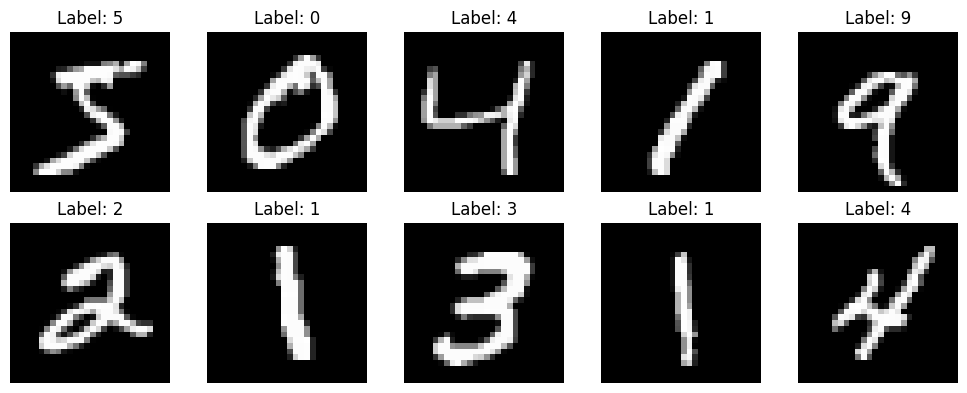

In [51]:
# Display some MNIST numbers

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [52]:
# 4. Normalize Images

x_train = x_train.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension
# From: (60000, 28, 28)
# To:   (60000, 28, 28, 1)

x_train = np.expand_dims(x_train, axis=-1)
x_val = np.expand_dims(x_val, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("\nAfter preprocessing:")
print("Training   :", x_train.shape)
print("Validation :", x_val.shape)
print("Testing    :", x_test.shape)



After preprocessing:
Training   : (60000, 28, 28, 1)
Validation : (5000, 28, 28, 1)
Testing    : (5000, 28, 28, 1)


In [53]:
# Create the CNN Model

model = tf.keras.Sequential([
    Conv2D(filters=32,kernel_size=(3, 3),padding="valid",activation='relu' ,input_shape=(28, 28, 1)),
    MaxPooling2D(pool_size=(3, 3), strides=(1, 1)),
    Conv2D(filters=64,kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(3, 3), strides=(1, 1)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation="softmax")
])


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [54]:
# Display Model Architecture

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 22, 22, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │     1,638,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,657,930 (6.32 MB)

 Trainable params: 1,657,930 (6.32 MB)

 Non-trainable params: 0 (0.00 B)

In [55]:
# Compile the Model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [56]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

In [57]:
# Train the CNN

history = model.fit(
    x_train,
    y_train,
    epochs=50,
    batch_size=128,
    callbacks=[early_stopping],
    validation_data=(x_val, y_val)
)

Epoch 1/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9558 - loss: 0.1460 - val_accuracy: 0.9878 - val_loss: 0.0417
Epoch 2/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9864 - loss: 0.0445 - val_accuracy: 0.9880 - val_loss: 0.0387
Epoch 3/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9898 - loss: 0.0320 - val_accuracy: 0.9904 - val_loss: 0.0330
Epoch 4/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9923 - loss: 0.0240 - val_accuracy: 0.9884 - val_loss: 0.0380
Epoch 5/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9938 - loss: 0.0200 - val_accuracy: 0.9886 - val_loss: 0.0349
Epoch 6/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9944 - loss: 0.0158 - val_accuracy: 0.9904 - val_loss: 0.0328
Epoch 7/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9951 - loss: 0.0141 - val_accuracy: 0.9888 - val_loss: 0.0357
Epoch 8/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9969 - loss: 0.0097 - val_accuracy: 0

In [58]:
# Evaluate the model on Test Data

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("\n===================================")
print("FINAL RESULTS")
print("===================================")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")



FINAL RESULTS
Test Loss     : 0.0330
Test Accuracy : 0.9892
Test Accuracy : 98.92%


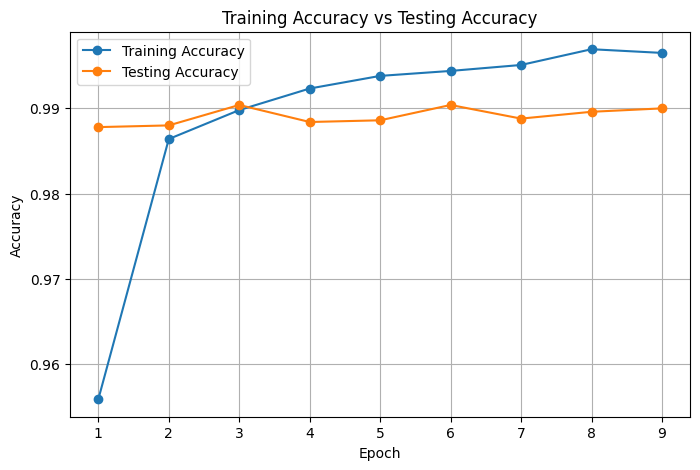

In [59]:
# Compare Training Accuracy vs Testing Accuracy

train_accuracy = history.history["accuracy"]
test_accuracy_history = history.history["val_accuracy"]

epochs = range(1, len(train_accuracy) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_accuracy,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    test_accuracy_history,
    marker="o",
    label="Testing Accuracy"
)

plt.title("Training Accuracy vs Testing Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()


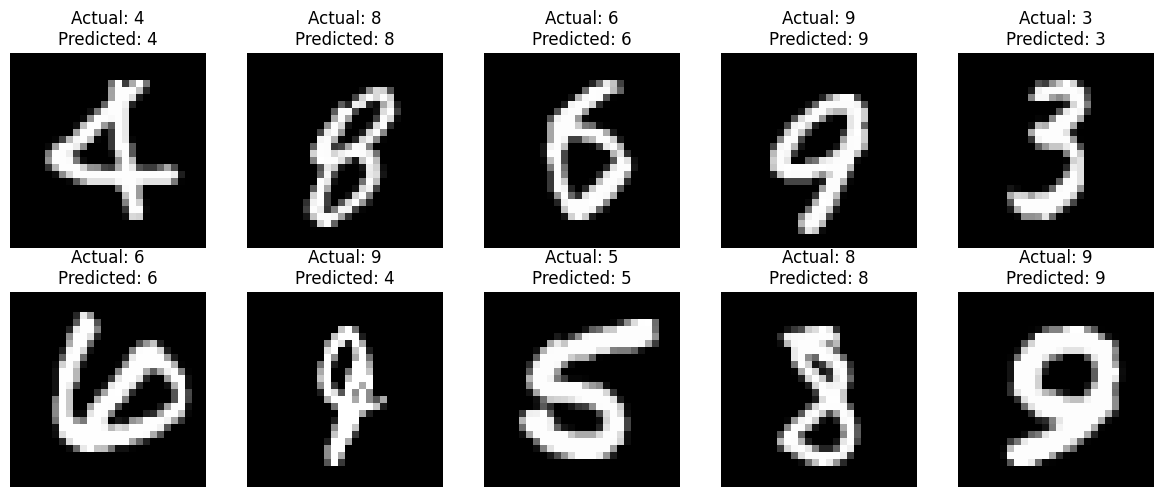

In [60]:
# Display Predictions

predictions = model.predict(x_test[:10], verbose=0)

predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(
        x_test[i].squeeze(),
        cmap="gray"
    )

    plt.title(
        f"Actual: {y_test[i]}\n"
        f"Predicted: {predicted_labels[i]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()